# 6. Modélisation et évaluation

L'objectif de cette étape est de construire un modèle capable de prédire si un client souscrira ou non à un dépôt à terme, à partir de ses caractéristiques et des informations disponibles avant le contact.

Nous commencerons par une régression logistique, un algorithme de classification supervisée adapté à la prédiction d'une variable binaire. Nous évaluerons ensuite ses performances à l'aide de plusieurs métriques, en tenant compte du déséquilibre entre les deux catégories de la variable cible.

Enfin, nous analyserons les résultats obtenus et sauvegarderons le modèle entraîné afin de pouvoir le réutiliser dans la suite du projet MLOps.

### 6.1. Chargement des données

Nous chargeons le jeu de données issu du Feature Engineering. Cette version contient les corrections et les transformations réalisées lors des étapes précédentes. Nous vérifions ses dimensions et son contenu avant de construire le modèle.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Chargement des données transformées
chemin_donnees = Path(
    "../data/interim/bank_marketing_feature_engineered.csv"
)

df = pd.read_csv(chemin_donnees, sep=";")

print("Dimensions du jeu de données :", df.shape)

print("\nAperçu des données :")
display(df.head())

Dimensions du jeu de données : (4119, 21)

Aperçu des données :


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,jamais_contacte
0,30,worker,married,basic,no,yes,no,cellular,spring,fri,...,2,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no,1
1,39,worker,single,high.school,no,no,no,telephone,spring,fri,...,4,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no,1
2,25,worker,married,high.school,no,yes,no,telephone,summer,wed,...,1,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no,1
3,38,worker,married,basic,no,no,no,telephone,summer,fri,...,3,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no,1
4,47,white_collar,married,university.degree,no,yes,no,cellular,nov,mon,...,1,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no,1


### 6.2. Vérification du jeu de données

Avant de construire le modèle, nous vérifions les types de variables, les valeurs manquantes, les doublons et la répartition de la cible. Ces contrôles permettent de repérer d'éventuelles anomalies qui pourraient influencer les résultats de la modélisation.

In [2]:
# Types des variables
print("Types des variables :")
display(df.dtypes)

# Valeurs manquantes
print("\nValeurs manquantes :")
display(df.isna().sum().sort_values(ascending=False))

# Doublons
print("\nNombre de doublons :", df.duplicated().sum())

# Répartition de la cible
print("\nRépartition de la cible :")
display(df["y"].value_counts(dropna=False))

print("\nRépartition en pourcentage :")
display(
    df["y"].value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Types des variables :


age                  int64
job                    str
marital                str
education              str
default                str
housing                str
loan                   str
contact                str
month                  str
day_of_week            str
duration             int64
campaign             int64
previous             int64
poutcome               str
emp.var.rate       float64
cons.price.idx     float64
cons.conf.idx      float64
euribor3m          float64
nr.employed        float64
y                      str
jamais_contacte      int64
dtype: object


Valeurs manquantes :


age                0
job                0
marital            0
education          0
default            0
housing            0
loan               0
contact            0
month              0
day_of_week        0
duration           0
campaign           0
previous           0
poutcome           0
emp.var.rate       0
cons.price.idx     0
cons.conf.idx      0
euribor3m          0
nr.employed        0
y                  0
jamais_contacte    0
dtype: int64


Nombre de doublons : 0

Répartition de la cible :


y
no     3668
yes     451
Name: count, dtype: int64


Répartition en pourcentage :


y
no     89.05
yes    10.95
Name: proportion, dtype: float64

### 6.3. Définition de la cible et des variables explicatives

La variable `y` indique si le client a souscrit ou non à un dépôt à terme. Elle constitue la variable cible que nous cherchons à prédire.

Les autres variables constituent les variables explicatives. Certaines informations sont toutefois exclues : `duration`, car la durée de l'appel n'est connue qu'à la fin de celui-ci, et `day_of_week`, qui n'est pas retenue dans notre sélection. La variable `pdays` est également exclue si elle est encore présente, puisque l'information relative aux contacts précédents est représentée par `jamais_contacte`.

In [3]:
# Définition de la cible
target = "y"

if target not in df.columns:
    raise ValueError("La variable cible 'y' est absente.")

if df[target].isna().any():
    raise ValueError("La variable cible contient des valeurs manquantes.")

# Vérification des modalités
print("Modalités de la cible :", df[target].unique())

if set(df[target].unique()) != {"no", "yes"}:
    raise ValueError("Les modalités de la cible ne sont pas celles attendues.")

# Variables à exclure
variables_a_exclure = [
    col for col in ["duration", "day_of_week", "pdays"]
    if col in df.columns
]

# Construction de X et y
X = df.drop(columns=[target] + variables_a_exclure)
y = df[target]

print("\nVariables exclues :", variables_a_exclure)
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

print("\nRépartition de la cible :")
display(y.value_counts(normalize=True).mul(100).round(2))

Modalités de la cible : <StringArray>
['no', 'yes']
Length: 2, dtype: str

Variables exclues : ['duration', 'day_of_week']
Dimensions de X : (4119, 18)
Dimensions de y : (4119,)

Répartition de la cible :


y
no     89.05
yes    10.95
Name: proportion, dtype: float64

### 6.4. Séparation des ensembles d'apprentissage et de test

Nous séparons les observations en deux ensembles : 80 % pour l'apprentissage et 20 % pour le test.

L'ensemble d'apprentissage sera utilisé pour ajuster le modèle et sélectionner ses paramètres. L'ensemble de test sera conservé pour mesurer ses performances sur des observations qui n'ont pas participé à l'apprentissage.

Nous utilisons une séparation stratifiée afin de conserver des proportions comparables de clients ayant souscrit et n'ayant pas souscrit dans les deux ensembles.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensions de X_train :", X_train.shape)
print("Dimensions de X_test :", X_test.shape)

print("\nRépartition de y_train (%) :")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nRépartition de y_test (%) :")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Dimensions de X_train : (3295, 18)
Dimensions de X_test : (824, 18)

Répartition de y_train (%) :


y
no     89.04
yes    10.96
Name: proportion, dtype: float64


Répartition de y_test (%) :


y
no     89.08
yes    10.92
Name: proportion, dtype: float64

### 6.5. Construction du prétraitement et du pipeline

Les variables numériques et catégorielles nécessitent des traitements différents. Nous utilisons `StandardScaler` pour standardiser les variables numériques et `OneHotEncoder` pour transformer les catégories en variables binaires.

Ces transformations sont intégrées à un pipeline avec la régression logistique. Cette organisation permet d'ajuster automatiquement le prétraitement sur les seules données utilisées pour l'apprentissage, notamment lors de la validation croisée.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identification des variables numériques
colonnes_numeriques = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identification des variables catégorielles
colonnes_categorielles = [
    col for col in X_train.columns
    if col not in colonnes_numeriques
]

print("Variables numériques :", colonnes_numeriques)
print("\nVariables catégorielles :", colonnes_categorielles)

# Prétraitement numérique
pipeline_numerique = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

# Prétraitement catégoriel
pipeline_categoriel = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

# Préprocesseur global
preprocesseur = ColumnTransformer([
    ("numerique", pipeline_numerique, colonnes_numeriques),
    ("categoriel", pipeline_categoriel, colonnes_categorielles)
])

# Pipeline complet
pipeline_logistique = Pipeline([
    ("pretraitement", preprocesseur),
    ("modele", LogisticRegression(max_iter=2000, random_state=42))
])

print("\nPipeline construit avec succès.")

Variables numériques : ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'jamais_contacte']

Variables catégorielles : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Pipeline construit avec succès.


### 6.6. Construction d'un modèle de référence

Avant d'évaluer la régression logistique, nous construisons un modèle de référence qui prédit systématiquement la classe majoritaire. Il permet de disposer d'un point de comparaison simple pour déterminer si notre modèle apporte une réelle amélioration.

Cette comparaison est particulièrement importante lorsque la variable cible est déséquilibrée.

In [9]:
from sklearn.linear_model import LogisticRegression

pipeline_logistique = Pipeline(
    steps=[
        ("pretraitement", preprocesseur),
        ("modele", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

print(pipeline_logistique)

Pipeline(steps=[('pretraitement',
                 ColumnTransformer(transformers=[('numerique',
                                                  Pipeline(steps=[('imputation',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardisation',
                                                                   StandardScaler())]),
                                                  ['age', 'campaign',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed',
                                                   'jamais_contacte']),
                                                 ('categoriel',
                                             

### 6.7. Entraînement du modèle

Nous entraînons le pipeline sur l'ensemble d'apprentissage. Le modèle apprend ainsi les relations entre les caractéristiques des clients et leur décision de souscrire ou non à un dépôt à terme.

In [10]:
pipeline_logistique.fit(X_train, y_train)

print("Entraînement terminé.")

Entraînement terminé.


### 6.8. Première évaluation sur l'ensemble de test

Nous utilisons le modèle entraîné pour prédire les classes des observations de test.

Nous calculons plusieurs métriques complémentaires : la précision, le rappel, le F1-score et l'exactitude globale. Nous examinons également la matrice de confusion pour comprendre les types d'erreurs commises par le modèle.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Prédictions des classes
y_pred = pipeline_logistique.predict(X_test)

# Calcul des métriques
metriques = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, pos_label="yes"),
    "Recall": recall_score(y_test, y_pred, pos_label="yes"),
    "F1-score": f1_score(y_test, y_pred, pos_label="yes")
}

display(pd.DataFrame(
    metriques.items(),
    columns=["Métrique", "Valeur"]
).round(3))

print("\nRapport de classification :")
print(classification_report(y_test, y_pred))

print("\nMatrice de confusion :")
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=["no", "yes"]),
    index=["Réel : no", "Réel : yes"],
    columns=["Prédit : no", "Prédit : yes"]
))

,Métrique,Valeur
0,Accuracy,0.898
1,Precision,0.636
2,Recall,0.156
3,F1-score,0.250



Rapport de classification :
              precision    recall  f1-score   support

          no       0.91      0.99      0.95       734
         yes       0.64      0.16      0.25        90

    accuracy                           0.90       824
   macro avg       0.77      0.57      0.60       824
weighted avg       0.88      0.90      0.87       824


Matrice de confusion :


,Prédit : no,Prédit : yes
Réel : no,726,8
Réel : yes,76,14


### 6.9. Évaluation à partir des probabilités

Au-delà de la prédiction d'une classe, la régression logistique fournit une probabilité de souscription pour chaque client.

Nous utilisons ces probabilités pour calculer l'aire sous la courbe ROC (ROC-AUC). Cette métrique mesure la capacité du modèle à distinguer les clients ayant souscrit de ceux n'ayant pas souscrit, indépendamment d'un seuil de classification particulier.

Nous examinons également la courbe ROC afin de visualiser cette capacité de discrimination.

ROC-AUC : 0.775


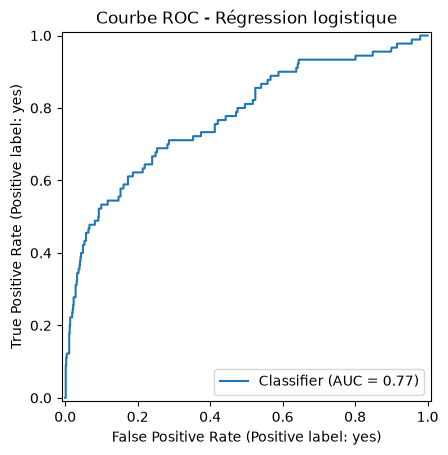

In [12]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Probabilité associée à la classe "yes"
indice_yes = list(pipeline_logistique.classes_).index("yes")
y_proba = pipeline_logistique.predict_proba(X_test)[:, indice_yes]

# Calcul du ROC-AUC
roc_auc = roc_auc_score(y_test, y_proba)

print(f"ROC-AUC : {roc_auc:.3f}")

# Courbe ROC
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    pos_label="yes"
)

plt.title("Courbe ROC - Régression logistique")
plt.show()

### 6.10. Analyse du seuil de classification

Par défaut, la classe positive est attribuée lorsque la probabilité estimée atteint au moins 0,5.

Cependant, ce seuil n'est pas nécessairement le plus adapté à notre problématique. Dans le cadre d'une campagne marketing, ne pas identifier un client susceptible de souscrire peut représenter une occasion commerciale manquée.

Nous étudions donc l'effet de différents seuils sur le rappel et la précision. Pour éviter de choisir le seuil directement sur les données de test, nous utilisons une validation croisée sur l'ensemble d'apprentissage.

In [13]:
from sklearn.model_selection import cross_val_predict

# Probabilités obtenues par validation croisée sur l'ensemble d'apprentissage
probabilites_cv = cross_val_predict(
    pipeline_logistique,
    X_train,
    y_train,
    cv=5,
    method="predict_proba"
)

indice_yes = list(np.unique(y_train)).index("yes")
proba_yes_cv = probabilites_cv[:, indice_yes]

# Comparaison de plusieurs seuils
seuils = np.arange(0.10, 0.71, 0.05)

resultats_seuils = []

for seuil in seuils:
    predictions = np.where(proba_yes_cv >= seuil, "yes", "no")

    resultats_seuils.append({
        "Seuil": seuil,
        "Precision": precision_score(
            y_train, predictions, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, pos_label="yes", zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, pos_label="yes", zero_division=0
        )
    })

df_seuils = pd.DataFrame(resultats_seuils)

display(df_seuils.round(3))

,Seuil,Precision,Recall,F1-score
0,0.10,0.283,0.634,0.392
1,0.15,0.376,0.565,0.452
2,0.20,0.441,0.515,0.475
3,0.25,0.467,0.465,0.466
4,0.30,0.480,0.407,0.441
5,0.35,0.508,0.349,0.414
6,0.40,0.532,0.299,0.383
7,0.45,0.571,0.247,0.344
8,0.50,0.597,0.213,0.314
9,0.55,0.645,0.191,0.295


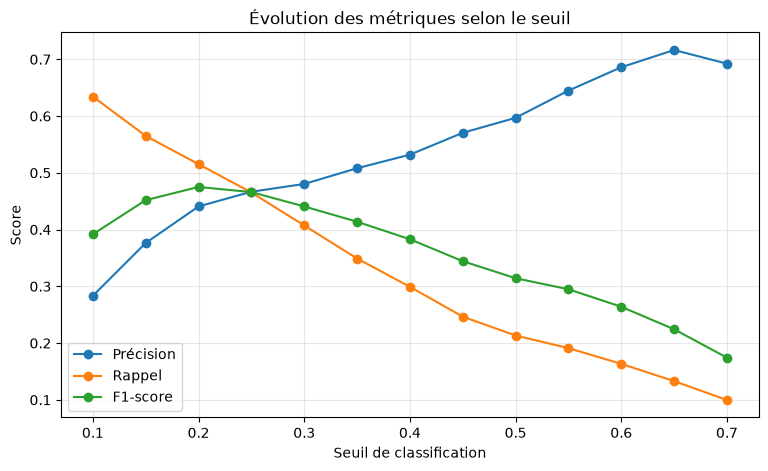

In [14]:
plt.figure(figsize=(9, 5))

plt.plot(
    df_seuils["Seuil"],
    df_seuils["Precision"],
    marker="o",
    label="Précision"
)

plt.plot(
    df_seuils["Seuil"],
    df_seuils["Recall"],
    marker="o",
    label="Rappel"
)

plt.plot(
    df_seuils["Seuil"],
    df_seuils["F1-score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Seuil de classification")
plt.ylabel("Score")
plt.title("Évolution des métriques selon le seuil")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 6.11. Choix du seuil et évaluation finale

À partir des résultats de validation croisée, nous retenons le seuil qui maximise le F1-score. Ce choix permet de rechercher un compromis entre la précision et le rappel.

Nous appliquons ensuite ce seuil au modèle entraîné sur l'ensemble d'apprentissage, puis évaluons ses performances sur l'ensemble de test, qui n'a pas participé au choix du seuil.

In [15]:
# Sélection du seuil maximisant le F1-score
meilleur_indice = df_seuils["F1-score"].idxmax()
seuil_optimal = df_seuils.loc[meilleur_indice, "Seuil"]

print(f"Seuil retenu : {seuil_optimal:.2f}")

# Prédictions sur le jeu de test avec le seuil retenu
y_pred_optimal = np.where(y_proba >= seuil_optimal, "yes", "no")

# Métriques finales
metriques_finales = {
    "Accuracy": accuracy_score(y_test, y_pred_optimal),
    "Precision": precision_score(
        y_test, y_pred_optimal, pos_label="yes", zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_optimal, pos_label="yes", zero_division=0
    ),
    "F1-score": f1_score(
        y_test, y_pred_optimal, pos_label="yes", zero_division=0
    ),
    "ROC-AUC": roc_auc
}

display(pd.DataFrame(
    metriques_finales.items(),
    columns=["Métrique", "Valeur"]
).round(3))

print("\nRapport de classification avec le seuil retenu :")
print(classification_report(
    y_test,
    y_pred_optimal,
    zero_division=0
))

Seuil retenu : 0.20


,Métrique,Valeur
0,Accuracy,0.887
1,Precision,0.482
2,Recall,0.456
3,F1-score,0.469
4,ROC-AUC,0.775



Rapport de classification avec le seuil retenu :
              precision    recall  f1-score   support

          no       0.93      0.94      0.94       734
         yes       0.48      0.46      0.47        90

    accuracy                           0.89       824
   macro avg       0.71      0.70      0.70       824
weighted avg       0.88      0.89      0.89       824



### 6.12. Comparaison avec un modèle de référence

Afin de mieux apprécier l'intérêt de notre modèle, nous le comparons à un classifieur de référence qui prédit systématiquement la classe majoritaire.

Cette comparaison permet de vérifier que la régression logistique apporte une réelle amélioration par rapport à une stratégie très simple.

In [16]:
from sklearn.dummy import DummyClassifier

# Modèle de référence
modele_reference = DummyClassifier(strategy="most_frequent")
modele_reference.fit(X_train, y_train)

predictions_reference = modele_reference.predict(X_test)

# Comparaison des métriques
comparaison = pd.DataFrame({
    "Modèle de référence": [
        accuracy_score(y_test, predictions_reference),
        precision_score(
            y_test, predictions_reference, pos_label="yes", zero_division=0
        ),
        recall_score(
            y_test, predictions_reference, pos_label="yes", zero_division=0
        ),
        f1_score(
            y_test, predictions_reference, pos_label="yes", zero_division=0
        )
    ],
    "Régression logistique": [
        accuracy_score(y_test, y_pred_optimal),
        precision_score(
            y_test, y_pred_optimal, pos_label="yes", zero_division=0
        ),
        recall_score(
            y_test, y_pred_optimal, pos_label="yes", zero_division=0
        ),
        f1_score(
            y_test, y_pred_optimal, pos_label="yes", zero_division=0
        )
    ]
}, index=["Accuracy", "Precision", "Recall", "F1-score"])

display(comparaison.round(3))

,Modèle de référence,Régression logistique
Accuracy,0.891,0.887
Precision,0.000,0.482
Recall,0.000,0.456
F1-score,0.000,0.469


### 6.13. Sauvegarde du modèle

Une fois l'évaluation terminée, nous sauvegardons le pipeline entraîné afin de pouvoir le réutiliser ultérieurement sans devoir recommencer le prétraitement et l'apprentissage.

Nous conservons également le seuil de classification retenu, car il fait partie des paramètres nécessaires à l'utilisation du modèle.

In [17]:
import joblib
import json
from pathlib import Path

# Création du dossier de sauvegarde
dossier_modeles = Path("../models")
dossier_modeles.mkdir(parents=True, exist_ok=True)

# Sauvegarde du pipeline entraîné
joblib.dump(
    pipeline_logistique,
    dossier_modeles / "logistic_regression.joblib"
)

# Sauvegarde du seuil retenu
with open(dossier_modeles / "threshold.json", "w", encoding="utf-8") as fichier:
    json.dump(
        {"seuil_optimal": float(seuil_optimal)},
        fichier,
        indent=4
    )

print("Modèle et seuil sauvegardés.")

Modèle et seuil sauvegardés.


### 6.14. Conclusion de la modélisation

Cette étape a permis de construire et d'évaluer un premier modèle de classification fondé sur la régression logistique.

L'évaluation a été réalisée à l'aide de plusieurs métriques afin de tenir compte du déséquilibre de la variable cible. L'analyse du seuil de classification a également permis d'étudier le compromis entre la précision et le rappel.

La comparaison avec un modèle de référence permet de déterminer si la régression logistique apporte une amélioration réelle. Enfin, le pipeline entraîné et le seuil retenu ont été sauvegardés pour être réutilisés dans les prochaines étapes du projet MLOps.